<a href="https://colab.research.google.com/github/dominicbarasa/Artificial-Intelligence-/blob/main/Week_4_Assignment_Mathematics_of_Data_Concrete_Strength.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Assignment | Exploring the Mathematics of Your Data

**Name:** Dominic Barasa
**Email:** [dbarasa195@gmail.com](mailto:dbarasa195@gmail.com)

**Course:** AI for Science and Engineering

**Project:** Prediction of Concrete Compressive Strength Using Machine Learning


## 1. Project Problem and Objective

My project investigates the prediction of concrete compressive strength using machine learning. The objective is to explore the numerical properties of concrete mix data and examine relationships between concrete ingredients, curing age, and measured compressive strength.

This assignment will use descriptive statistics, covariance, correlation, and a scatter plot to understand the dataset and prepare for future machine learning modelling.

The ultimate aim is to investigate whether concrete mix characteristics and age can help predict concrete compressive strength in megapascals (MPa).


In [6]:
# Import the libraries needed for data analysis
import pandas as pd
import matplotlib.pyplot as plt

# Load the concrete compressive strength dataset
url = "https://raw.githubusercontent.com/HansenHan/ML_UCI_Concrete_Compressive_Strength/main/Concrete_Data.csv"

df = pd.read_csv(url)

# Display the original column names
print("Original column names:")
print(df.columns.tolist())

# Display the first five rows
display(df.head())

Original column names:
['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer', 'Coarse Aggregate', 'Fine Aggregate', 'Age', 'Concrete compressive strength']


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [7]:
# Give the dataset columns shorter, easier-to-use names
df.columns = [
    "Cement",
    "Blast_Furnace_Slag",
    "Fly_Ash",
    "Water",
    "Superplasticizer",
    "Coarse_Aggregate",
    "Fine_Aggregate",
    "Age",
    "Compressive_Strength"
]

# Check the dataset size
print("Dataset size:", df.shape)

# Display the first five rows with the new column names
display(df.head())

Dataset size: (1030, 9)


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Compressive_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## 2. Selected Numerical Variables

The four numerical variables selected for this analysis are cement content, water content, concrete age, and concrete compressive strength.

These variables are relevant because concrete composition and curing age may be associated with the strength achieved by concrete. The variables will be explored using descriptive statistics to understand their central values and variability.


In [8]:
# Select the four variables for statistical analysis
variables = [
    "Cement",
    "Water",
    "Age",
    "Compressive_Strength"
]

# Calculate descriptive statistics for each variable
statistics = pd.DataFrame({
    "Mean": df[variables].mean(),
    "Median": df[variables].median(),
    "Range": df[variables].max() - df[variables].min(),
    "Variance": df[variables].var(),
    "Standard Deviation": df[variables].std()
})

# Display the results rounded to two decimal places
display(statistics.round(2))

,Mean,Median,Range,Variance,Standard Deviation
Cement,281.17,272.90,438.00,10921.58,104.51
Water,181.57,185.00,125.20,456.00,21.35
Age,45.66,28.00,364.00,3990.44,63.17
Compressive_Strength,35.82,34.44,80.27,279.08,16.71


## 3. Covariance and Correlation

Cement content and concrete compressive strength were selected to investigate whether there is a statistical relationship between the amount of cement in a concrete mixture and its measured strength.

Covariance indicates whether the two variables tend to vary in the same or opposite directions. Correlation measures the direction and strength of their linear relationship, with values ranging from -1 to +1.


In [9]:
# Select the two variables for relationship analysis
cement = df["Cement"]
strength = df["Compressive_Strength"]

# Calculate covariance
covariance = cement.cov(strength)

# Calculate Pearson correlation
correlation = cement.corr(strength)

# Display the results
print("Covariance between cement and compressive strength:",
      round(covariance, 2))

print("Correlation between cement and compressive strength:",
      round(correlation, 3))

Covariance between cement and compressive strength: 869.14
Correlation between cement and compressive strength: 0.498


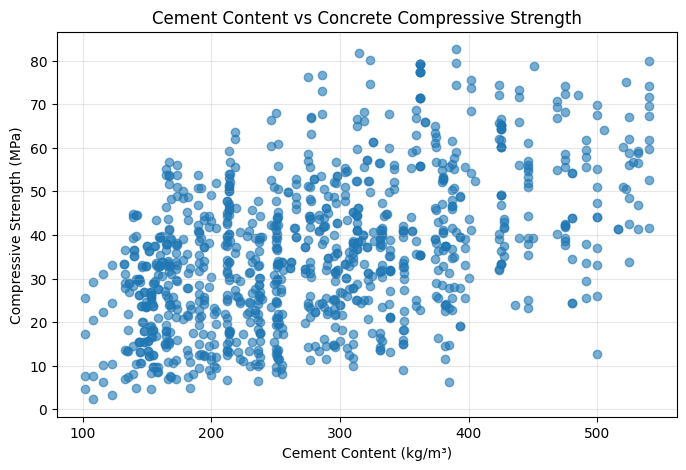

In [10]:
# Create a scatter plot of cement content against concrete strength
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Cement"],
    df["Compressive_Strength"],
    alpha=0.6
)

plt.title("Cement Content vs Concrete Compressive Strength")
plt.xlabel("Cement Content (kg/m³)")
plt.ylabel("Compressive Strength (MPa)")
plt.grid(True, alpha=0.3)

plt.show()

## 4. Interpretation of Descriptive Statistics

The mean shows the average value of each selected variable, while the median indicates the middle observation. Comparing the mean and median can help indicate whether the data may be skewed.

The range shows the difference between the highest and lowest observations. Variance and standard deviation describe how widely the values are distributed around the mean.

Cement content, water content, age, and compressive strength have different units and numerical scales. Therefore, their means and standard deviations should be interpreted in the context of each variable rather than compared directly without considering their units.

These statistics provide an initial understanding of the dataset and help identify variability that may be important when developing a future machine learning model.


## 5. Interpretation of Covariance, Correlation and the Scatter Plot

Covariance indicates whether cement content and concrete compressive strength tend to vary in the same direction or in opposite directions. Its magnitude depends on the units and scales of the variables.

The correlation coefficient measures the direction and strength of the linear relationship between cement content and concrete compressive strength. The calculated coefficient and scatter plot will be used to determine whether the observed relationship is positive or negative and whether it appears weak, moderate, or strong.

**Correlation does not necessarily mean causation.** Even if cement content and compressive strength are positively correlated, this alone does not prove that increasing cement content causes a particular increase in strength. Other factors, such as water content, aggregate proportions, admixtures, and curing age, may also influence concrete strength.


## 6. Mathematical Representation: Input → Function/Model → Output

Let:

* \(x\) = cement content in kg/m³.
* \(f\) = a function or machine learning model.
* \(\hat{y}\) = predicted concrete compressive strength in MPa.

The mathematical expression is:

$$
x \longrightarrow f(x) \longrightarrow \hat{y}
$$

Or, more specifically:

$$
\widehat{\text{Strength}} = f(\text{Cement Content})
$$

The model would use cement content as an input and produce an estimated compressive strength as an output. This is a simplified illustration; a more realistic model would use multiple inputs, including water content, aggregate quantities, admixtures, and concrete age.


## 7. Dataset Source

**Dataset:** Concrete Compressive Strength

**Source:** UCI Machine Learning Repository

**URL:** https://archive.ics.uci.edu/dataset/165/concrete%2Bcompressive%2Bstrength

The dataset contains concrete mixture characteristics, curing age, and measured compressive strength. It is used in this assignment to explore descriptive statistics and relationships between numerical variables.
